# Nonlinear Boundary Value Problems

Many steady-state problems are nonlinear: reaction terms such as $e^u$, conductivities that depend on the
temperature, equilibria of reaction-diffusion systems. In this notebook we solve such problems with
`solve_nonlinear`, which applies Newton's method to a residual $F(u) = 0$ that we write down with the usual
*numgrids* tools.

We will

1. solve the **Bratu problem** and compare with its exact solution,
2. find **both** of its solutions, follow the whole solution branch through its fold with
   **continuation**, and see which of the solutions are **stable**,
3. speed things up with an **exact Jacobian** written in operator algebra,
4. solve the Bratu problem on the **full unit disk**, and
5. compute the temperature in a plate with a **temperature-dependent conductivity**.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

from numgrids import *
from numgrids.nonlinear import continuation, linear_stability

## 1. The Bratu Problem

The Bratu problem

$$
u'' + \lambda e^{u} = 0, \qquad u(0) = u(1) = 0,
$$

is a classic model of thermal runaway in a reactive slab: the reaction heats the material, and the reaction
rate grows exponentially with the temperature. For $\lambda = 1$ we pass the residual
$F(u) = u'' + \lambda e^u$, an initial guess and the boundary conditions. With `verbose=True` we watch Newton's
method converge quadratically.

In [2]:
grid = Grid(x=chebyshev(41, 0, 1))
x = grid.coords

u = solve_nonlinear(grid, lambda u: grid.diff(u, 2) + np.exp(u), u0=0, bcs=0, verbose=True)

Newton step 1: |F| = 1.020e-02, |du| = 1.395e-01, damping = 1
Newton step 2: |F| = 6.166e-07, |du| = 1.045e-03, damping = 1
Newton step 3: |F| = 1.434e-11, |du| = 5.879e-08, damping = 1
Newton step 4: |F| = 6.930e-13, |du| = 6.182e-14, damping = 1


The exact solution is $u(x) = -2 \ln\left(\cosh\bigl((x - \tfrac12)\tfrac{\theta}{2}\bigr) /
\cosh\tfrac{\theta}{4}\right)$, where $\theta$ solves $\theta = \sqrt{2\lambda}\,\cosh(\theta/4)$. That
equation has two roots, which belong to two different solutions. We come back to that below.

In [3]:
def bratu_exact(x, lam, branch="lower"):
    f = lambda t: t - np.sqrt(2 * lam) * np.cosh(t / 4)
    theta = brentq(f, 0, 5) if branch == "lower" else brentq(f, 5, 30)
    return -2 * np.log(np.cosh((x - 0.5) * theta / 2) / np.cosh(theta / 4))

print("max. error:", np.max(np.abs(u - bratu_exact(x, 1.0))))

max. error: 3.635980405647388e-15


## 2. Two Solutions and Continuation

Newton's method converges to a solution *near* the initial guess. Starting from a large bump, we find the
second solution of the Bratu problem for the same $\lambda = 1$:

max. error: 1.0816236795108125e-11


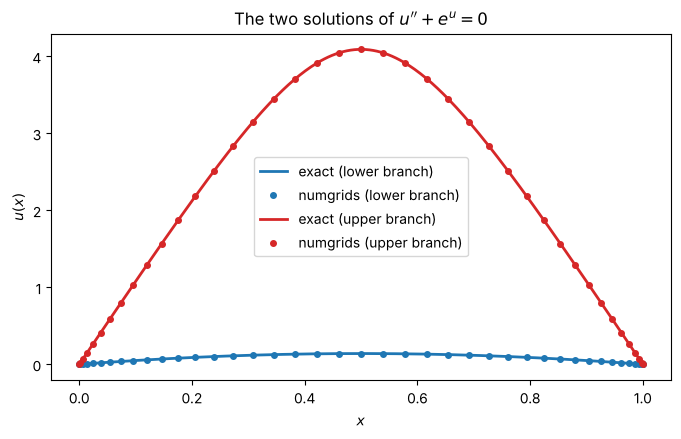

In [4]:
upper = solve_nonlinear(grid, lambda u: grid.diff(u, 2) + np.exp(u),
                        u0=4 * np.sin(np.pi * x), bcs=0)
print("max. error:", np.max(np.abs(upper - bratu_exact(x, 1.0, "upper"))))

fig, ax = plt.subplots(figsize=(8, 4.5))
xf = np.linspace(0, 1, 300)
for sol, name, color in [(u, "lower", "tab:blue"), (upper, "upper", "tab:red")]:
    ax.plot(xf, bratu_exact(xf, 1.0, name), color=color, lw=2, label=f"exact ({name} branch)")
    ax.plot(x, sol, "o", color=color, ms=4, label=f"numgrids ({name} branch)")
ax.set_xlabel("$x$")
ax.set_ylabel("$u(x)$")
ax.set_title(r"The two solutions of $u'' + e^u = 0$")
ax.legend()
plt.show()

How are the two solutions related, and what happens for other values of $\lambda$? `continuation` follows
a branch of solutions of $F(u, \lambda) = 0$, starting from the solution for one value of the parameter.
The residual takes the parameter as its last argument. We start from the trivial solution $u = 0$ at
$\lambda = 0$ and take 150 steps of length `ds = 0.05` along the branch.

With `stability=3`, the continuation also computes the three leading eigenvalues of the Jacobian at every
point. They tell whether the solution is stable as a steady state of the reaction-diffusion equation
$u_t = u'' + \lambda e^u$: a small perturbation grows like $e^{\sigma t}$ with the eigenvalues $\sigma$, so
the solution is stable if all eigenvalues are negative.

In [5]:
def bratu(u, lam):
    return grid.diff(u, 2) + lam * np.exp(u)

branch = continuation(grid, bratu, u0=0, param=0, bcs=0, ds=0.05, max_steps=150, stability=3)
max_u = branch.measure(np.max)

print(branch)
print("solutions:", branch.u.shape, "(point on the branch, x)")
print("lambda:   ", np.round(branch.params[:3], 4), "...", np.round(branch.params[71:76], 4),
      "...", np.round(branch.params[-3:], 4))
print("max u:    ", np.round(max_u[:3], 4), "...", np.round(max_u[71:76], 4),
      "...", np.round(max_u[-3:], 4))
print("stable:   ", branch.stable[:3], "...", branch.stable[71:76], "...", branch.stable[-3:])
print("folds:    ", branch.folds)

ContinuationResult(151 points, parameter from 0 to 0.440556, 1 fold(s), 74 stable point(s), success=True)
solutions: (151, 41) (point on the branch, x)
lambda:    [0.     0.0499 0.0997] ... [3.4707 3.4995 3.5134 3.5077 3.4868] ... [0.4947 0.4672 0.4406]
max u:     [0.     0.0063 0.0126] ... [1.0111 1.0833 1.169  1.258  1.3392] ... [5.1511 5.2336 5.3175]
stable:    [ True  True  True] ... [ True  True  True False False] ... [False False False]
folds:     [73]


`branch.params` holds the parameters and `branch.u` the solutions along the branch, and
`branch.measure(func)` reduces every solution to a number, here its maximum. The parameter increases up to
$\lambda \approx 3.51$ and then *decreases* again, while the solutions keep growing: the branch turns back
in a **fold**. `branch.folds` lists the points of the branch where this happens. Up to the fold the
solutions are stable, behind it they are not.

The fold itself lies between two points of the branch. `continuation` locates it there, by solving for the
point of the branch where the parameter is stationary: `branch.fold_params` and `branch.fold_u` hold the
parameters and the solutions at the folds. We compare with the exact curve, which is known in terms of the
parameter $\theta$ of the exact solution, $\lambda = \theta^2 / \bigl(2 \cosh^2 (\theta/4)\bigr)$ and
$\max u = 2 \ln \cosh (\theta/4)$. Its fold is at $\lambda_c = 3.513830719\ldots$

In [6]:
k = branch.folds[0]
lam_fold = branch.fold_params[0]
max_u_fold = branch.fold_u[0].max()
print(f"point {k} of the branch:  lambda = {branch.params[k]:.10f},  max u = {max_u[k]:.8f}")
print(f"located fold:            lambda = {lam_fold:.10f},  max u = {max_u_fold:.8f}")

# The exact fold: the maximum of lambda(theta) is at theta = 4 s with s tanh(s) = 1
s = brentq(lambda s: s * np.tanh(s) - 1, 1, 2)
lam_c = 8 * s**2 / np.cosh(s) ** 2
print(f"exact:                   lambda = {lam_c:.10f},  max u = {2 * np.log(np.cosh(s)):.8f}")

# All points of the branch must lie on the exact curve lambda(max u)
theta = 4 * np.arccosh(np.exp(max_u / 2))
print("largest deviation of the branch from the exact curve:",
      f"{np.max(np.abs(branch.params - theta**2 / (2 * np.cosh(theta / 4) ** 2))):.1e}")

point 73 of the branch:  lambda = 3.5134239741,  max u = 1.16899409
located fold:            lambda = 3.5138307191,  max u = 1.18684217
exact:                   lambda = 3.5138307191,  max u = 1.18684217
largest deviation of the branch from the exact curve: 2.2e-10


The *bifurcation diagram* shows $\max u$ against $\lambda$, as usual with a solid line for the stable and a
dashed line for the unstable solutions. The two solutions for $\lambda = 1$ from above are the lower and the
upper part of one and the same branch, and beyond the fold there is no solution at all.

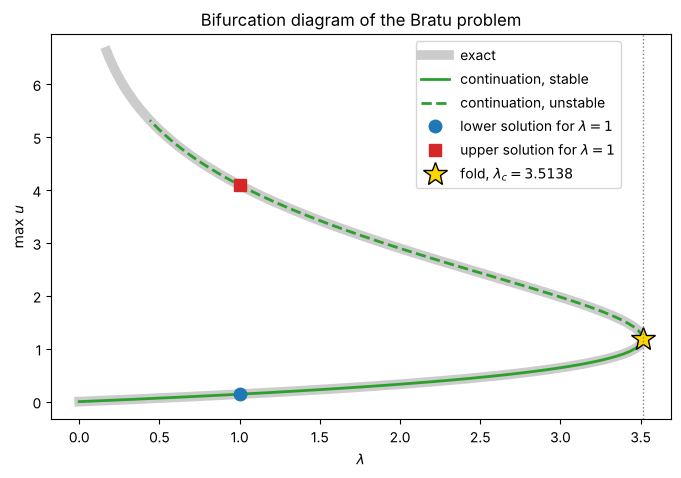

In [7]:
theta = np.linspace(0.01, 16, 500)
lam_exact = theta**2 / (2 * np.cosh(theta / 4) ** 2)
max_exact = 2 * np.log(np.cosh(theta / 4))

# The stable and the unstable part of the branch meet in the fold
stable, unstable = branch.stable, ~branch.stable
lam_stable = np.append(branch.params[stable], lam_fold)
lam_unstable = np.append(lam_fold, branch.params[unstable])

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(lam_exact, max_exact, "-", color="0.8", lw=7, label="exact")
ax.plot(lam_stable, np.append(max_u[stable], max_u_fold), "-", color="tab:green", lw=2,
        label="continuation, stable")
ax.plot(lam_unstable, np.append(max_u_fold, max_u[unstable]), "--", color="tab:green", lw=2,
        label="continuation, unstable")
ax.plot(1.0, u.max(), "o", color="tab:blue", ms=9, label=r"lower solution for $\lambda = 1$")
ax.plot(1.0, upper.max(), "s", color="tab:red", ms=8, label=r"upper solution for $\lambda = 1$")
ax.plot(lam_fold, max_u_fold, "*", color="gold", mec="k", ms=18,
        label=rf"fold, $\lambda_c = {lam_fold:.4f}$")
ax.axvline(lam_fold, color="gray", ls=":", lw=1)
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel(r"$\max\, u$")
ax.set_title("Bifurcation diagram of the Bratu problem")
ax.legend(loc="upper right", bbox_to_anchor=(0.93, 1.0))
plt.show()

The stability changes exactly at the fold: there the leading eigenvalue `branch.eigenvalues[:, 0]` crosses
zero. Behind the fold one perturbation grows, and the temperature either runs away or falls back to the
lower solution. For a single solution, `linear_stability` gives the same information.

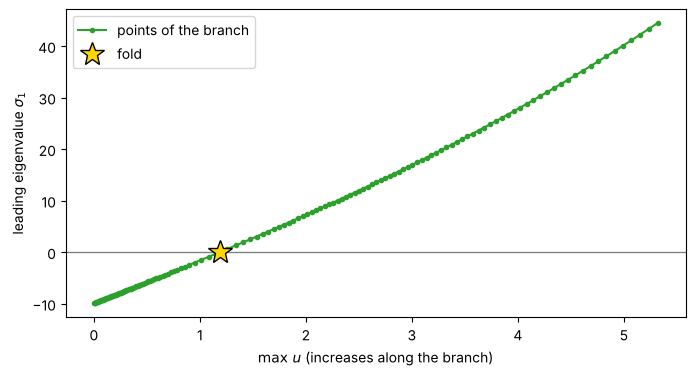

[Bifurcation(fold at param = 3.513830719, between the points 73 and 74)]
lower solution for lambda = 1: StabilityResult(stable, growth rate -8.7397)
upper solution for lambda = 1: StabilityResult(unstable, 1 unstable mode, growth rate 28.873)


In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.axhline(0, color="gray", lw=1)
ax.plot(max_u, branch.eigenvalues[:, 0], "o-", color="tab:green", ms=3, label="points of the branch")
ax.plot(max_u_fold, 0, "*", color="gold", mec="k", ms=18, label="fold")
ax.set_xlabel(r"$\max\, u$ (increases along the branch)")
ax.set_ylabel(r"leading eigenvalue $\sigma_1$")
ax.legend()
plt.show()

print(branch.bifurcations)
for name, solution in [("lower", u), ("upper", upper)]:
    print(f"{name} solution for lambda = 1:", linear_stability(grid, bratu, solution, bcs=0, param=1.0))

Could we have traced this diagram with `solve_nonlinear` alone, increasing $\lambda$ step by step and using
each solution as the initial guess for the next? Only in pieces. Stepping in the parameter cannot pass a
fold: the Jacobian is singular there, and behind it the parameter has to decrease again. One would have to
stop short of the fold and start the upper branch from a separately found solution. `continuation` steps
along the curve $(u, \lambda)$ itself (*pseudo-arclength continuation*) and treats the parameter as an
unknown like the solution, so it passes the fold in one go.

Beyond the fold, for $\lambda > \lambda_c$, Newton's method cannot converge. `solve_nonlinear` then raises a `NonlinearSolverError`,
which carries the last iterate and the residual history:

In [9]:
try:
    solve_nonlinear(grid, lambda u: bratu(u, 4.0), 0, bcs=0, maxiter=20)
except NonlinearSolverError as err:
    print(err)
    print("last residuals:", np.round(err.residuals[-3:], 3))

Newton's method did not converge in 20 steps (residual 1.935e+00). Try a better initial guess (e.g. continuation from a nearby problem).
last residuals: [1.933 1.933 1.935]


## 3. An Exact Jacobian

Newton's method needs the Jacobian $J = \partial F / \partial u$. By default, `solve_nonlinear` approximates it
by finite differences, which costs one residual evaluation per grid point and Newton step. For larger grids
we pass the exact Jacobian instead. Thanks to the operator algebra it looks just like the formula: for
$F(u) = \nabla^2 u + \lambda e^u$, the Jacobian is $J = \nabla^2 + \lambda e^u$ (an operator plus a
multiplication). Here is the Bratu problem on a square:

In [10]:
square = Grid(x=chebyshev(40, 0, 1), y=chebyshev(40, 0, 1))
L = square.laplacian_operator()
lam = 6.0

start = time.perf_counter()
u_fd = solve_nonlinear(square, lambda u: L(u) + lam * np.exp(u), 0, bcs=0)
t_fd = time.perf_counter() - start

start = time.perf_counter()
u_ex = solve_nonlinear(square, lambda u: L(u) + lam * np.exp(u), 0, bcs=0,
                       jacobian=lambda u: L + lam * np.exp(u))
t_ex = time.perf_counter() - start

print(f"finite-difference Jacobian: {t_fd:.3f} s")
print(f"exact Jacobian:             {t_ex:.3f} s")
print("difference of the solutions:", np.max(np.abs(u_fd - u_ex)))

finite-difference Jacobian: 2.167 s
exact Jacobian:             0.623 s
difference of the solutions: 2.886579864025407e-15


## 4. The Bratu Problem on the Full Disk

Everything works on curvilinear grids, too. On the unit disk, the Bratu problem
$\nabla^2 u + \lambda e^u = 0$ with $u = 0$ on the rim has the exact solution

$$
u(r) = \ln \frac{8\mu / \lambda}{(1 + \mu r^2)^2}, \qquad (1 + \mu)^2 = \frac{8\mu}{\lambda}.
$$

A `PolarGrid` with a `radial` axis covers the full disk including its center. The only boundary is the rim.

max. error: 1.3350431871117507e-13


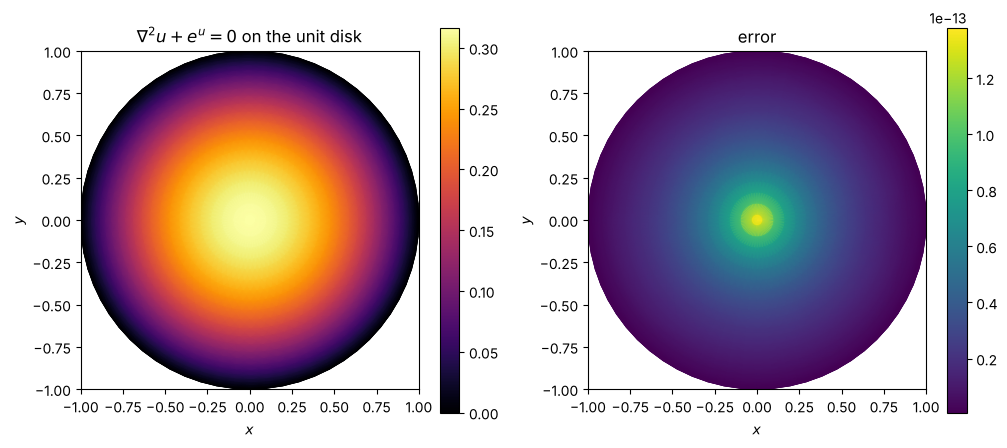

In [11]:
disk = PolarGrid(radial(24, 1.0), periodic(64))
L = disk.laplacian_operator()
lam = 1.0

u = solve_nonlinear(disk, lambda u: L(u) + lam * np.exp(u), 0, bcs=0,
                    jacobian=lambda u: L + lam * np.exp(u))

R, _ = disk.meshed_coords
mu = (4 / lam - 1) - np.sqrt((4 / lam - 1) ** 2 - 1)        # the smaller root
exact = np.log(8 * mu / lam / (1 + mu * R**2) ** 2)
print("max. error:", np.max(np.abs(u - exact)))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
disk.plot(u, ax=axes[0], cmap="inferno")
axes[0].set_title(r"$\nabla^2 u + e^u = 0$ on the unit disk")
disk.plot(np.abs(u - exact), ax=axes[1], cmap="viridis")
axes[1].set_title("error")
plt.show()

## 5. A Plate with Temperature-Dependent Conductivity

In many materials the thermal conductivity depends on the temperature. The steady temperature in a plate
heated uniformly with power density $q$ then satisfies

$$
\nabla \cdot \bigl(k(u)\, \nabla u\bigr) + q = 0 .
$$

We take $k(u) = 1 + u^2$ (a conductivity that grows with the temperature) and keep three edges at temperature 0.
The top edge is insulated, $\partial u / \partial n = 0$. The residual is a direct transcription of the
equation.

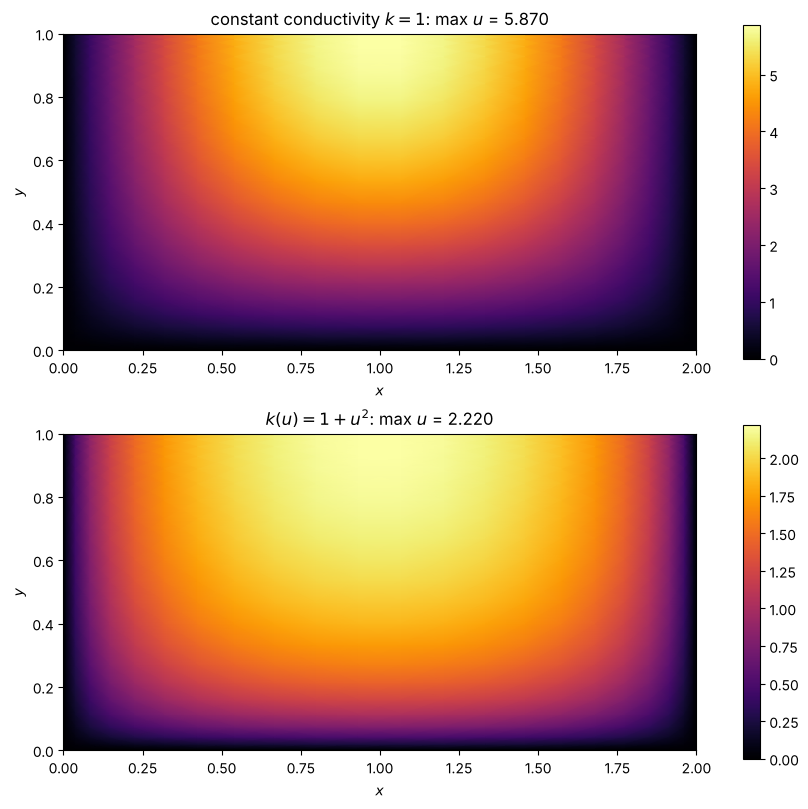

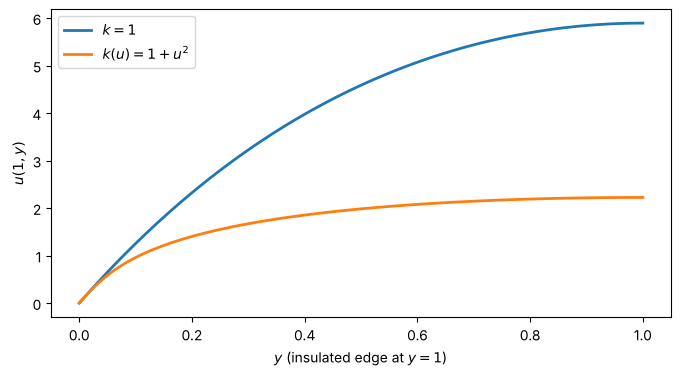

In [12]:
plate = Grid(x=chebyshev(24, 0, 2), y=chebyshev(24, 0, 1))
q = 20.0

def k(u):
    return 1 + u**2

def residual(u):
    flux = [k(u) * g for g in plate.gradient(u)]
    return plate.divergence(*flux) + q

bcs = {"x_low": 0, "x_high": 0, "y_low": 0, "y_high": Neumann(0)}
u = solve_nonlinear(plate, residual, 0, bcs=bcs)

# For comparison: constant conductivity k = 1 (a linear problem)
u_lin = plate.laplacian_operator().solve(-q, bcs=bcs)

fig, axes = plt.subplots(2, 1, figsize=(8, 8), constrained_layout=True)
for ax, f, title in [(axes[0], u_lin, "constant conductivity $k = 1$"),
                     (axes[1], u, "$k(u) = 1 + u^2$")]:
    plate.plot(f, ax=ax, cmap="inferno")
    ax.set_title(f"{title}: max $u$ = {f.max():.3f}")
    ax.set_aspect("equal")
plt.show()

# Temperature along the vertical center line x = 1
y_line = np.linspace(0, 1, 100)
points = np.column_stack([np.ones_like(y_line), y_line])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(y_line, plate.interpolate(u_lin, points, method="spectral"), lw=2, label="$k = 1$")
ax.plot(y_line, plate.interpolate(u, points, method="spectral"), lw=2, label="$k(u) = 1 + u^2$")
ax.set_xlabel("$y$ (insulated edge at $y = 1$)")
ax.set_ylabel("$u(1, y)$")
ax.legend()
plt.show()

The hotter the material, the better it conducts. So the plate with temperature-dependent conductivity stays
cooler than the one with constant conductivity, and its temperature profile is flatter. On both plates the
temperature is highest at the insulated top edge, where its normal derivative vanishes: no heat can escape
there.

## Summary

`solve_nonlinear` solves nonlinear boundary value problems with Newton's method:

```python
u = solve_nonlinear(grid, residual, u0, bcs=..., jacobian=...)
```

1. The **residual** is an ordinary function of grid-shaped arrays, written with `grid.diff`,
   `grid.gradient`, operators and NumPy functions.
2. The **initial guess** selects the solution when there are several of them. `continuation` follows a
   branch of solutions while a parameter changes, through folds, and finds how the solutions are
   connected. It locates the folds and, with `stability=k`, tells which solutions are stable;
   `linear_stability` does so for a single solution.
3. Boundary conditions take the same compact forms as for `solve` and `evolve` (Dirichlet, Neumann, Robin).
4. Without further information the Jacobian is computed by finite differences. An **exact Jacobian** is
   quickly written with operator algebra and is much faster for larger grids.
5. Everything works on **curvilinear grids**, including the full disk.

Coupled systems of equations are supported as well, see the
[user guide](https://maroba.github.io/numgrids/guide/nonlinear.html).